# Pseudo-time trajectories (ArchR `addTrajectory` port)

Epione ports ArchR's supervised trajectory analysis:

| ArchR | Epione |
|---|---|
| `addTrajectory` | `epi.tl.add_trajectory` |
| `getTrajectory` | `epi.tl.get_trajectory` |
| `plotTrajectoryHeatmap` / `trajectoryHeatmap` | `epi.pl.plot_trajectory_heatmap`, `epi.tl.trajectory_heatmap_matrix` (= `returnMatrix = TRUE`) |
| `correlateTrajectories` | `epi.tl.correlate_trajectories` |
| `plotTrajectory` | `epi.pl.plot_trajectory` |

**How a supervised trajectory is fitted.** You give an ordered list of cell groups
(here `C11 → C10 → C5`). Within each group, cells further than the 90th distance
quantile from the group centroid are dropped; every remaining cell gets an
*initial time* `x + (1 - q)` (distance quantile to the next group's centroid; the
last group uses the previous centroid). For each dimension of the reduced space a
cubic smoothing spline (`stats::smooth.spline(spar = 1)`) is fitted against this
time, giving a curve through the space. Every cell is then projected onto its
nearest spline points (k = 3), and the rank of that position becomes the
pseudo-time in `(0, 100]`. Epione re-implements `smooth.spline` itself, so the
spline agrees with R to ~1e-10.

We use the **ArchR Hematopoiesis tutorial data** (BMMC + CD34⁺ BMMC + PBMC,
10,660 cells), exported from the ArchR project (`IterativeLSI`, `UMAP`,
`Clusters`, `GeneScoreMatrix`, chromVAR `MotifMatrix` with JASPAR2020 motifs).

In [1]:
%matplotlib inline
import pathlib, time
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
from anndata import AnnData
from IPython.display import display, Image

import epione as epi

DEV = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev')
TABLES = DEV / 'fixture' / 'tables'        # tables exported from the ArchR project
REF = DEV / 'work' / 'trajectory' / 'ref'  # ArchR 1.0.3 reference outputs (parity section)
print(epi.__file__)

/scratch/users/steorra/analysis/25_epione/epione_dev/wt/trajectory/epione/__init__.py


## Load the data

`cells.tsv` carries ArchR's `cellColData` (clusters, UMAP), `lsi.tsv` the
30-dimensional IterativeLSI, and `GeneScoreMatrix.mtx` the gene scores
(genes × cells). Feature names follow ArchR's `seqnames:name` convention.

In [2]:
cells = pd.read_csv(TABLES / 'cells.tsv', sep='\t', index_col=0)
lsi = pd.read_csv(TABLES / 'lsi.tsv', sep='\t', index_col=0).loc[cells.index]

gs = sio.mmread(TABLES / 'GeneScoreMatrix.mtx').tocsr()
gfeat = pd.read_csv(TABLES / 'GeneScoreMatrix_features.tsv', sep='\t')
gcells = pd.Index(open(TABLES / 'GeneScoreMatrix_cells.txt').read().split())
var = gfeat.set_index(gfeat.seqnames + ':' + gfeat.name)

adata = AnnData(X=gs[:, gcells.get_indexer(cells.index)].T.tocsr(), obs=cells[['Sample', 'Clusters', 'nFrags', 'TSSEnrichment']].copy(), var=var)
adata.obsm['X_iterative_lsi'] = lsi.values
adata.obsm['X_umap'] = cells[['UMAP1', 'UMAP2']].values
adata

AnnData object with n_obs × n_vars = 10660 × 23127
    obs: 'Sample', 'Clusters', 'nFrags', 'TSSEnrichment'
    var: 'seqnames', 'start', 'end', 'strand', 'name', 'idx'
    obsm: 'X_iterative_lsi', 'X_umap'

## Choose the trajectory groups

Mean gene scores of lineage markers per cluster: `C11` is a CD34⁺ CRHBP⁺
progenitor cluster, `C10` expresses the GMP markers MPO / ELANE, and `C5` the
monocyte genes CEBPB / CD14 / LYZ. The trajectory is therefore
`["C11", "C10", "C5"]`, the myeloid branch of the ArchR tutorial.

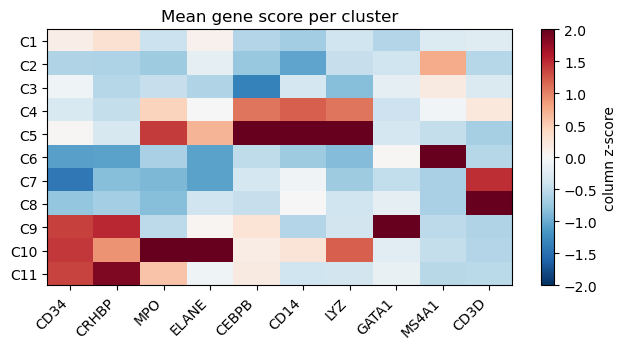

In [3]:
markers = ['CD34', 'CRHBP', 'MPO', 'ELANE', 'CEBPB', 'CD14', 'LYZ', 'GATA1', 'MS4A1', 'CD3D']
name2var = pd.Series(adata.var_names, index=adata.var['name'].values)
cols = [name2var[g] for g in markers]
mean = pd.DataFrame(adata[:, cols].X.toarray(), index=adata.obs_names, columns=markers).groupby(adata.obs['Clusters']).mean()
mean = mean.loc[sorted(mean.index, key=lambda c: int(c[1:]))]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
z = (mean - mean.mean()) / mean.std()
im = ax.imshow(z.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(markers))); ax.set_xticklabels(markers, rotation=45, ha='right')
ax.set_yticks(range(len(mean))); ax.set_yticklabels(mean.index)
fig.colorbar(im, ax=ax, label='column z-score'); ax.set_title('Mean gene score per cluster')
plt.tight_layout(); plt.show()

## `add_trajectory`

Fit in the IterativeLSI space (ArchR's default `reducedDims`). The pseudo-time
goes to `adata.obs['MyeloidU']`; cells off the trajectory get `NaN`.
`return_df=True` also returns ArchR's `saveDF` frame (distance to the spline
and the fractional spline index).

In [4]:
%%time
TRAJ = ['C11', 'C10', 'C5']
df = epi.tl.add_trajectory(adata, TRAJ, groupby='Clusters', use_rep='X_iterative_lsi',
                           key_added='MyeloidU', return_df=True)
display(df.head())
print(adata.obs.groupby('Clusters', observed=True)['MyeloidU'].median().dropna().round(1))

[add_trajectory] 4767 cells placed on C11 -> C10 -> C5 -> adata.obs['MyeloidU']


,Distance,DistanceIdx,Trajectory
scATAC_BMMC_R1#AGTTACGAGAACGTCG-1,1.606827,2034.520861,39.983218
scATAC_BMMC_R1#CCGTACTCAAGTGGCA-1,1.977487,2386.131773,47.409272
scATAC_BMMC_R1#GCTCACTTCCAACAAC-1,0.804715,2773.999056,55.191945
scATAC_BMMC_R1#AGCGATTCATTCACCC-1,1.854702,2044.794601,40.067128
scATAC_BMMC_R1#GCTGTTCAGATGTTCC-1,1.689957,2401.365301,47.765890


Clusters
C10    41.2
C11    16.9
C5     74.3
Name: MyeloidU, dtype: float64
CPU times: user 2.42 s, sys: 201 ms, total: 2.62 s
Wall time: 859 ms


## `plot_trajectory`

The left panel shows the UMAP coloured by pseudo-time, with ArchR's arrow (cells
binned by pseudo-time, centroids smoothed with a 5-bin rolling mean). The right
panel plots the value against pseudo-time.

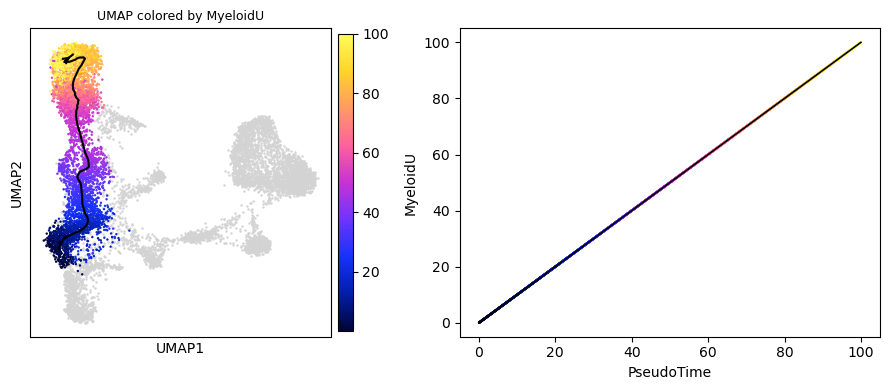

In [5]:
fig, axes = epi.pl.plot_trajectory(adata, trajectory_key='MyeloidU', basis='X_umap', show=False)
plt.show()

Colouring by a gene follows ArchR exactly: the values are clipped to their
1–99 % quantiles and transformed with `log2(x + 1)`. ArchR also smooths gene
scores with MAGIC weights (`getImputeWeights`). Epione accepts the same
cell × cell weights through `impute_weights=`; here we plot raw scores.

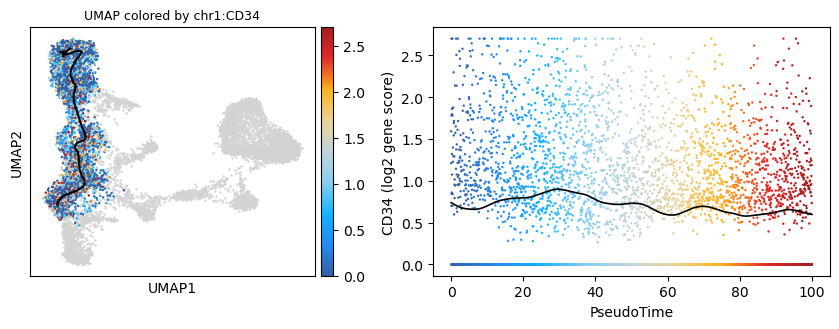

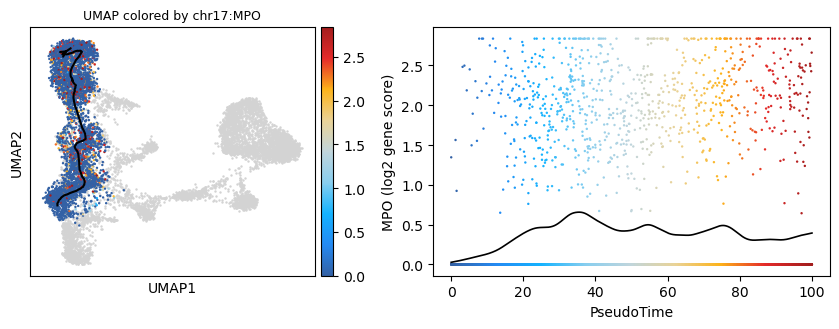

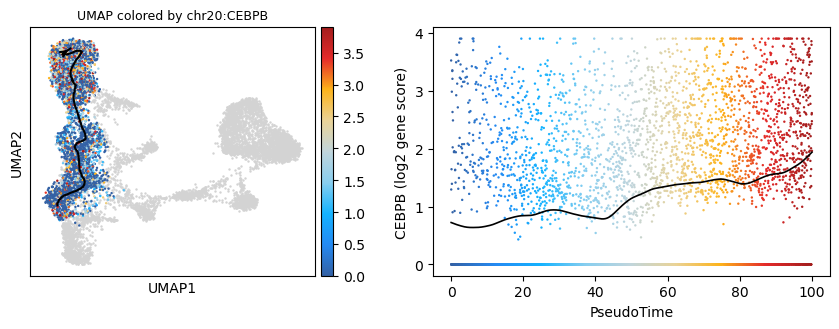

In [6]:
for g in ['CD34', 'MPO', 'CEBPB']:
    fig, axes = epi.pl.plot_trajectory(adata, trajectory_key='MyeloidU', color_by=name2var[g],
                                       basis='X_umap', figsize=(8.5, 3.4), show=False)
    axes[1].set_ylabel(f'{g} (log2 gene score)')
    plt.show()

## `get_trajectory` + `plot_trajectory_heatmap`

`get_trajectory` sums cells into 100 pseudo-time bins, normalises each bin to
10,000, applies `log2(x + 1)` and smooths with an 11-bin centred rolling mean.
The heatmap keeps the top 10 % most variable features, z-scores each row and
orders rows by the bin where they peak. Gene-score heatmaps use ArchR's
`blueYellow` palette.

In [7]:
%%time
trajGSM = epi.tl.get_trajectory(adata, 'MyeloidU', trajectory_label='Clusters', matrix_name='GeneScoreMatrix')
trajGSM

CPU times: user 487 ms, sys: 56.8 ms, total: 544 ms
Wall time: 544 ms


AnnData object with n_obs × n_vars = 100 × 23127
    obs: 'label'
    var: 'seqnames', 'start', 'end', 'strand', 'name', 'idx'
    uns: 'trajectory_params'
    layers: 'mat', 'smoothMat'

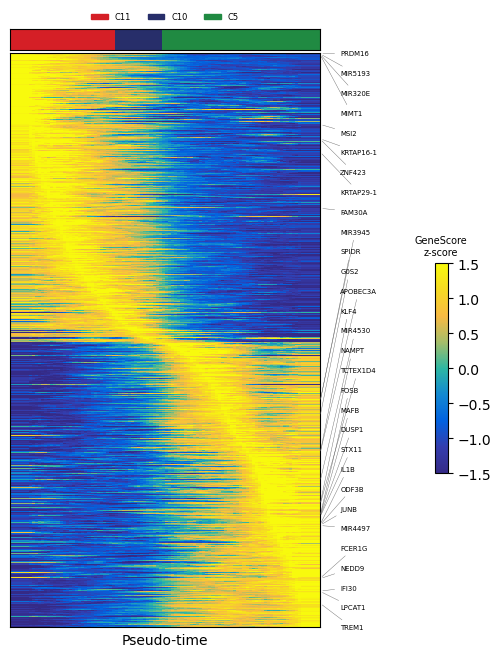

(2312, 100)


In [8]:
fig, mat = epi.pl.plot_trajectory_heatmap(trajGSM, var_cutoff=0.9, label_top=30, color_columns=True,
                                          title='GeneScore\nz-score', show=False)
plt.show()
print(mat.shape)

### chromVAR motif trajectory

For deviation z-scores, set `log2_norm=False, scale_to=None`. ArchR's
`MotifMatrix` stores both `deviations` and `z`. The heatmap uses the z-scores,
which is what `plotTrajectoryHeatmap` selects by default. Motif IDs are
translated to TF names with the JASPAR2020 table.

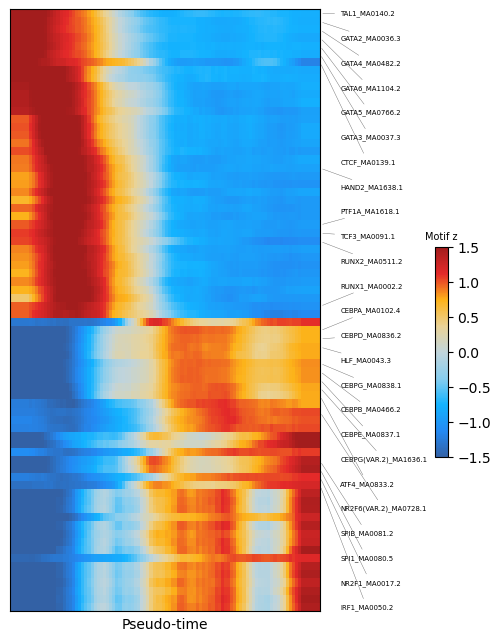

In [9]:
id2name = pd.read_csv(REF / 'jaspar_id2name.tsv', sep='\t').set_index('id')['name']
mm = {k: pd.read_csv(TABLES / f'MotifMatrix_{k}.tsv.gz', sep='\t', index_col=0)[adata.obs_names].T
      for k in ('deviations', 'z')}
tf = lambda m: f'{id2name[m].upper()}_{m}'
adata.obsm['MotifMatrix'] = pd.concat([mm['deviations'].rename(columns=lambda m: f'deviations:{tf(m)}'),
                                      mm['z'].rename(columns=lambda m: f'z:{tf(m)}')], axis=1)
trajMM = epi.tl.get_trajectory(adata, 'MyeloidU', use_rep='MotifMatrix', log2_norm=False, scale_to=None,
                               matrix_name='MotifMatrix')
trajMM.var['name'] = [v.split(':', 1)[1] for v in trajMM.var_names]
trajMMz = trajMM[:, trajMM.var_names.str.startswith('z:')].copy()
fig, mat = epi.pl.plot_trajectory_heatmap(trajMMz, var_cutoff=0.9, label_top=25, title='Motif z', show=False)
plt.show()

## `correlate_trajectories`: TF activity vs gene score

Features are paired by name after removing the `_…` / `-…` suffixes (`CEBPB_MA0466.2`
→ `CEBPB`). Pearson correlation is computed on the **unsmoothed** binned matrices.
Pairs with r > 0.5 whose variance is in the top 20 % of both trajectories are kept.

In [10]:
trajGSM.var['name'] = trajGSM.var['name'].astype(str)
cor = epi.tl.correlate_trajectories(trajGSM, trajMM, name_key1='name', name_key2='name')
pf = cor['correlatedMappings'].sort_values('Correlation', ascending=False)
print(len(cor['allMappings']), 'name-matched pairs;', len(pf), 'correlated')
pf[['matchname1', 'name2', 'Correlation', 'VarAssay1', 'VarAssay2', 'FDR']].head(15)

1450 name-matched pairs; 33 correlated


,matchname1,name2,Correlation,VarAssay1,VarAssay2,FDR
22,NR4A2,z:NR4A2_MA0160.1,0.855775,0.996757,0.934987,1.209838e-26
20,MEIS1,z:MEIS1_MA0498.2,0.852377,0.996325,0.800938,1.737734e-26
13,NR1D1,z:NR1D1_MA1531.1,0.795263,0.993601,0.886059,1.044095e-20
8,WT1,z:WT1_MA1627.1,0.769881,0.982229,0.813673,1.055678e-18
1,ATF3,z:ATF3_MA0605.2,0.767414,0.985126,0.905496,1.516914e-18
29,CEBPD,z:CEBPD_MA0836.2,0.737402,0.995806,0.999330,2.084402e-16
31,NFIL3,z:NFIL3_MA0025.2,0.736589,0.993730,0.977882,2.224688e-16
3,GATA3,z:GATA3_MA0037.3,0.723294,0.886885,0.991957,1.321570e-15
6,NFKB2,z:NFKB2_MA0778.1,0.721817,0.991309,0.906166,1.442161e-15
4,GATA3,z:GATA3_MA0037.3,0.720106,0.990963,0.991957,1.784956e-15


ArchR's integrative heatmap: for each correlated pair, sum the row z-scores of
the gene score and the motif, order rows on that combined matrix, then draw both
heatmaps in the same row order.

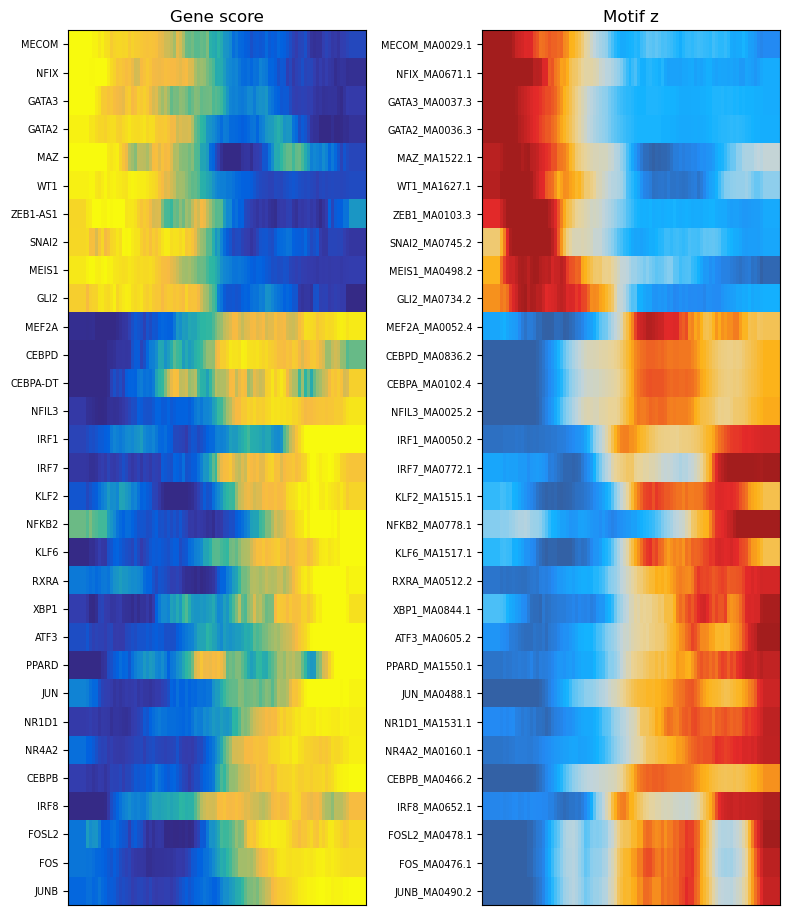

In [11]:
pairs = pf[pf['name2'].str.startswith('z:')].drop_duplicates('name1').drop_duplicates('name2')
g2 = trajGSM[:, pairs['name1'].values].copy()
m2 = trajMM[:, pairs['name2'].values].copy()
zs = lambda a: (a - a.mean(0)) / a.std(0, ddof=1)
comb = g2.copy(); comb.layers['smoothMat'] = zs(g2.layers['smoothMat']) + zs(m2.layers['smoothMat'])
order = epi.tl.trajectory_heatmap_matrix(comb, var_cutoff=0).index
row_order = [list(g2.var_names).index(n) for n in order]
hg = epi.tl.trajectory_heatmap_matrix(g2, row_order=row_order)
hm = epi.tl.trajectory_heatmap_matrix(m2, row_order=row_order)

from epione.pl._trajectory import _archr_cmap
fig, axes = plt.subplots(1, 2, figsize=(8, 0.25 * len(hg) + 1.5))
for ax, h, cm, t in ((axes[0], hg, 'blueYellow', 'Gene score'), (axes[1], hm, 'solarExtra', 'Motif z')):
    ax.imshow(h.values, aspect='auto', cmap=_archr_cmap(cm), vmin=-1.5, vmax=1.5, interpolation='nearest')
    ax.set_title(t); ax.set_xticks([])
    ax.set_yticks(range(len(h))); ax.set_yticklabels([n.split(':')[-1] for n in h.index], fontsize=7)
plt.tight_layout(); plt.show()

## Parity vs ArchR

`tests/parity/trajectory/r_reference.R` runs ArchR 1.0.3 on the same project
(`addTrajectory` with LSI, with UMAP and with `useAll = TRUE`, then
`getTrajectory`, `plotTrajectoryHeatmap(returnMatrix = TRUE)`,
`correlateTrajectories` and `plotTrajectory`). It dumps every output, plus
`addTrajectory`'s internal steps, at full double precision.
`parity_trajectory.py` recomputes all of it with Epione. All outputs are
deterministic, so the gates (pre-registered in `MANIFEST.md`) are class 1:
max |Δ| ≤ 1e-8, and discrete outputs must match exactly.

In [12]:
import importlib.util, sys
spec = importlib.util.spec_from_file_location('parity_trajectory', '../../../tests/parity/trajectory/parity_trajectory.py')
par = importlib.util.module_from_spec(spec); spec.loader.exec_module(par)
t0 = time.time(); res = par.run(str(REF), str(TABLES)); print(f'{time.time() - t0:.1f}s')
tab = pd.DataFrame({'value': res}).rename_axis('output')
tab['gate'] = ['exact (=1)' if k.endswith(par.GATES['exact_suffixes']) else '|Δ| ≤ 1e-8' for k in tab.index]
tab['pass'] = [par.passed(k, v) for k, v in res.items()]
pd.set_option('display.max_rows', 100)
print('ALL PASS' if tab['pass'].all() else 'FAILURES'); tab

10.9s
ALL PASS


,value,gate,pass
output,,,
lsi.initialTime,0.000000e+00,|Δ| ≤ 1e-8,True
lsi.initialTime_names,1.000000e+00,exact (=1),True
lsi.matSpline,8.389556e-11,|Δ| ≤ 1e-8,True
lsi.knnIdx_identical,1.000000e+00,exact (=1),True
lsi.knnDist,2.070222e-11,|Δ| ≤ 1e-8,True
lsi.cells_identical,1.000000e+00,exact (=1),True
lsi.Distance,2.070233e-11,|Δ| ≤ 1e-8,True
lsi.DistanceIdx,9.094947e-13,|Δ| ≤ 1e-8,True
lsi.Trajectory,2.842171e-14,|Δ| ≤ 1e-8,True


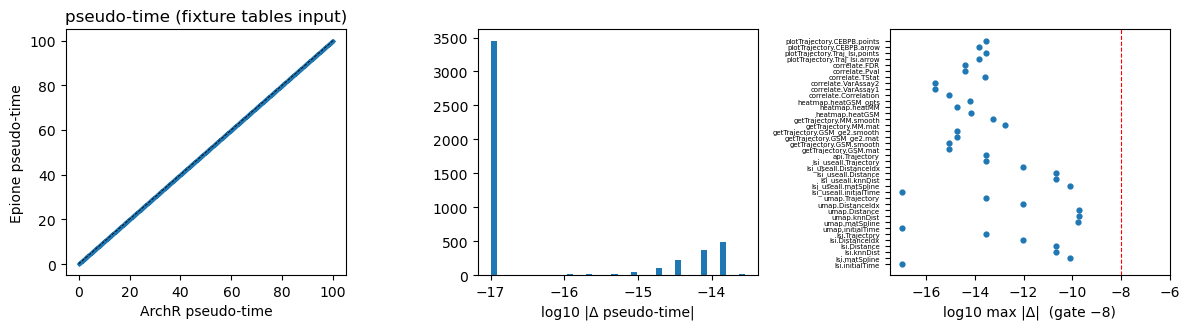

In [13]:
r = pd.read_csv(REF / 'trajectory_lsi.tsv', sep='\t', index_col=0)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].scatter(r['Trajectory'], adata.obs.loc[r.index, 'MyeloidU'], s=2, rasterized=True)
axes[0].plot([0, 100], [0, 100], 'k--', lw=0.6)
axes[0].set_xlabel('ArchR pseudo-time'); axes[0].set_ylabel('Epione pseudo-time')
axes[0].set_title('pseudo-time (fixture tables input)')
d = np.abs(adata.obs.loc[r.index, 'MyeloidU'].values - r['Trajectory'].values)
axes[1].hist(np.log10(d + 1e-17), bins=40); axes[1].set_xlabel('log10 |Δ pseudo-time|')
num = tab[tab.gate != 'exact (=1)']['value'].astype(float)
axes[2].scatter(np.log10(num.values + 1e-17), range(len(num)), s=12); axes[2].axvline(-8, color='r', ls='--', lw=0.8)
axes[2].set_xlim(-17.5, -6)
axes[2].set_yticks(range(len(num))); axes[2].set_yticklabels(num.index, fontsize=5)
axes[2].set_xlabel('log10 max |Δ|  (gate −8)')
plt.tight_layout(); plt.show()

The **Epione pseudo-time** above starts from the 15-digit text export
(`lsi.tsv`). It still matches ArchR to < 1e-10. The parity table uses ArchR's
binary dumps of the same inputs.

ArchR's own figures (rendered from the reference run) for visual comparison:

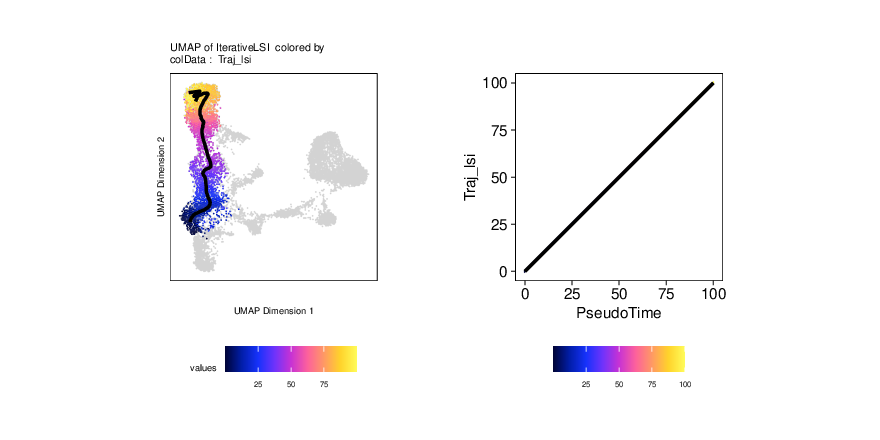

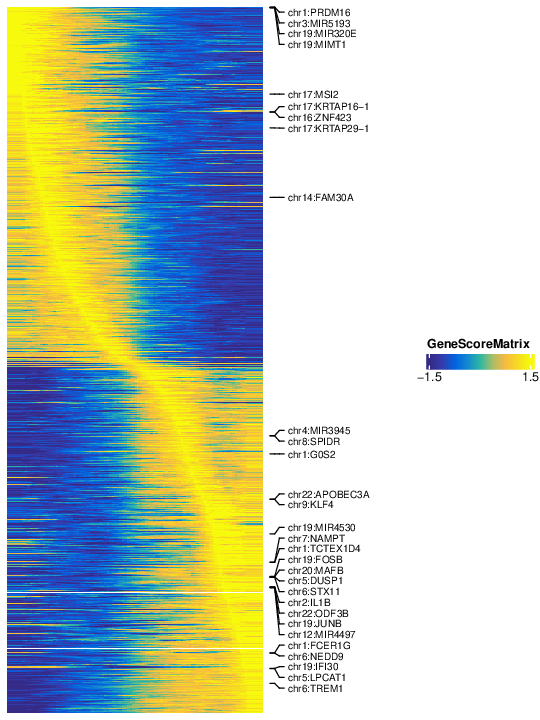

In [14]:
display(Image(filename=str(REF / 'archr_plotTrajectory-1.png'), width=650))
display(Image(filename=str(REF / 'archr_trajectory_heatmap.png'), width=380))

### Notes

* ArchR passes both `df = 250` and `spar = 1` to `smooth.spline`. R ignores
  `df` when `spar` is given, so Epione only exposes `spar`.
* `epi.pl.plot_trajectory` draws its panel-2 trend with the ported smoothing
  spline. ArchR's trend line is `ggplot2::geom_smooth` (an mgcv GAM), which is
  only visual and is not parity-gated.
* `addSlingShotTrajectories` / `addMonocleTrajectory` (wrappers around the R
  packages) are not ported here.